Para criar um exemplo de um código que evidencia o espraiamento do campo elétrico nas bordas de um capacitor, podemos simular um capacitor de placas paralelas em 2D e observar como o campo elétrico se comporta nas bordas. Vou criar um modelo simplificado onde as placas do capacitor são representadas por linhas de potencial fixo em uma grade 2D, e o espraiamento do campo elétrico será visível perto das bordas dessas "placas".

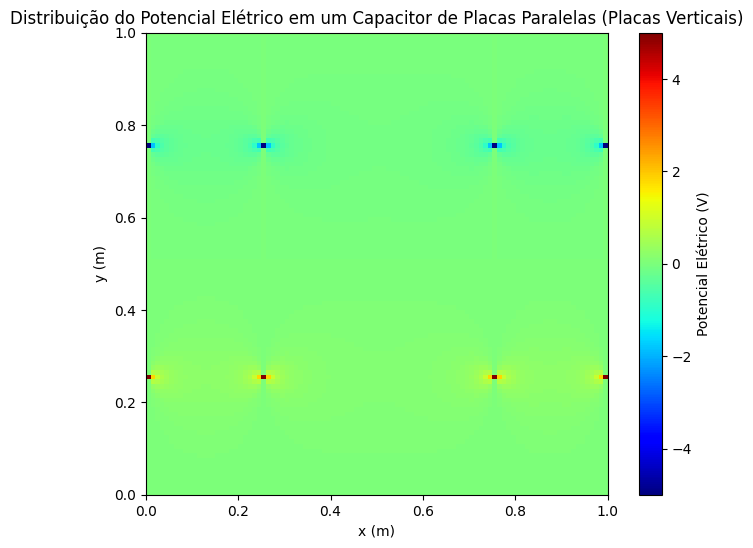

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros
N_x, N_y = 100, 100  # Número de pontos na grade
L_x, L_y = 1.0, 1.0  # Tamanho da área de simulação
V_left_plate = 5.0   # Potencial na placa da esquerda (volts)
V_right_plate = -5.0 # Potencial na placa da direita (volts)
plate_width = N_x // 4  # Largura das placas
max_iter = 10000  # Número máximo de iterações
tolerance = 1e-6  # Tolerância para a convergência

# Inicializando a grade
V = np.zeros((N_x, N_y))

# Definindo as placas do capacitor (como linhas verticais finas)
left_plate_y = N_y // 4
right_plate_y = 3 * N_y // 4

V[left_plate_y, :] = V_left_plate
V[right_plate_y, :] = V_right_plate

# Método das diferenças finitas
for _ in range(max_iter):
    V_old = V.copy()
    for i in range(1, N_x - 1):
        for j in range(1, N_y - 1):
            if not (j == left_plate_y or j == right_plate_y):
                V[i, j] = 0.25 * (V_old[i+1, j] + V_old[i-1, j] + V_old[i, j+1] + V_old[i, j-1])

    # Checa a convergência
    if np.max(np.abs(V - V_old)) < tolerance:
        break

# Plotando o potencial elétrico
plt.figure(figsize=(8, 6))
plt.imshow(V, extent=[0, L_x, 0, L_y], origin='lower', cmap='jet')
plt.colorbar(label='Potencial Elétrico (V)')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Distribuição do Potencial Elétrico em um Capacitor de Placas Paralelas (Placas Verticais)')
plt.show()
